# Librerias


In [1]:
import sys
import os

# Agrega la carpeta raíz del proyecto al path de Python.
sys.path.append(os.path.abspath(os.path.join('../')))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from src.Modelo_ANN import Modelo_ANN


I0000 00:00:1794268788.203961   14319 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794268801.021032   14319 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


In [2]:
print(tf.config.list_physical_devices("GPU"))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Instancia para modelado


In [3]:
modelo_acciones = Modelo_ANN(tipo='multiclase')


# Carga de sets de datos


In [4]:
modelo_acciones.load_data('../data/proceced/archivos_parquet/vectoria_acciones.parquet')
modelo_acciones.data = modelo_acciones.data.drop(columns=['escenario'])


In [5]:
categorias_acciones = [
    'monitoreo_normal',
    'eliminacion_criaderos',
    'fumigacion_focalizada',
    'alerta_sanitaria',
]

modelo_acciones.set_categorical_columns(
    columna='recomendacion',
    categorias=categorias_acciones,
    cat_codes=True,
)


In [6]:
entradas_acciones = list(modelo_acciones.data.drop(columns='recomendacion').columns)


In [7]:
modelo_acciones.set_scaled_partitions(
    variables_entrada=entradas_acciones,
    variables_salida=['recomendacion'],
    stratify=False,
)


In [8]:
modelo_acciones.x_train


array([[0.17120781, 0.70732723, 0.05444258, ..., 0.27272727, 0.6975945 ,
        1.        ],
       [0.15209435, 0.70732723, 0.05444258, ..., 0.27272727, 0.6975945 ,
        0.        ],
       [0.11834079, 0.70732723, 0.05444258, ..., 0.27272727, 0.6975945 ,
        0.        ],
       ...,
       [0.1594144 , 0.15487094, 0.04954886, ..., 0.70454545, 0.27835052,
        1.        ],
       [0.15412769, 0.15487094, 0.04954886, ..., 0.70454545, 0.27835052,
        0.        ],
       [0.13338756, 0.15487094, 0.04954886, ..., 0.70454545, 0.27835052,
        0.        ]], shape=(1645, 7))

In [9]:
modelo_acciones.y_val


,recomendacion
fecha_inicio_semana,
2023-04-30,0
2023-04-30,0
2023-04-30,0
2023-04-30,2
2023-04-30,0
...,...
2024-11-24,2
2024-11-24,3
2024-11-24,3


# Configuracion de flujo y entrenamiento


In [10]:
beta = 0.999
pesos_dict = {}
for c in np.unique(modelo_acciones.y_train):
    n_j = np.sum(modelo_acciones.y_train.to_numpy() == c)
    pesos_dict[c] = (1.0 - beta) / (1.0 - np.power(beta, n_j))

modelo_acciones.preparar_experimento(
    45
).model_flow_settings(
    capas = 3,
    fun_act = 'PReLU',
    loss = 'sparse_categorical_crossentropy',
    optimizer = 'adam',
    n_output = len(categorias_acciones),
    dropout = 0.5,
    fun_out = 'softmax',
    leakyrelu_negative_slope = None,
    n_down = 1,
    metrics = ['sparse_categorical_accuracy'],
).model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu (PReLU)                 │ (None, 7)              │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_1 (PReLU)               │ (None, 7)              │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_2 (PReLU)               │ (None, 7)              │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            32 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221 (884.00 B)

 Trainable params: 221 (884.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
os.makedirs('../models/ANN_Models/Acciones/checkpoints', exist_ok=True)

modelo_acciones.start_training(
    epochs = 600,
    w_balance = True,
    w_dict = None,
    batch_size = 800,
    callbacks = [
        EarlyStopping(
            monitor='val_loss',
            mode='min',
            verbose=1,
            patience=10,
            restore_best_weights=True,
        ),
        ModelCheckpoint(
            filepath='../models/ANN_Models/Acciones/checkpoints/ann_acciones.keras',
            monitor='val_loss',
            mode='min',
            save_best_only=True,
        ),
    ],
)
losses = pd.DataFrame(modelo_acciones.model.history.history)


🚀 Iniciando el entrenamiento...

Epoch 1/600


E0000 00:00:1794268806.716652   14319 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 655ms/step - loss: 1.4404 - sparse_categorical_accuracy: 0.2584 - val_loss: 1.4165 - val_sparse_categorical_accuracy: 0.0819
Epoch 2/600
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 1.4336 - sparse_categorical_accuracy: 0.1198 - val_loss: 1.4145 - val_sparse_categorical_accuracy: 0.0819
Epoch 3/600
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 1.4330 - sparse_categorical_accuracy: 0.1793 - val_loss: 1.4129 - val_sparse_categorical_accuracy: 0.0795
Epoch 4/600
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 1.4401 - sparse_categorical_accuracy: 0.1775 - val_loss: 1.4111 - val_sparse_categorical_accuracy: 0.0747
Epoch 5/600
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 1.4425 - sparse_categorical_accuracy: 0.1562 - val_loss: 1.4089 - val_sparse_categorical_accuracy: 0.0699
Epoch 6/600
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 1.4401 - sparse_categorical_accuracy: 0.1672 - val_loss: 1.4065 - val_sparse_categorical_accuracy: 0.0627
Epoch 7/600
3/3 ━━━━━━━━━━

<Axes: >

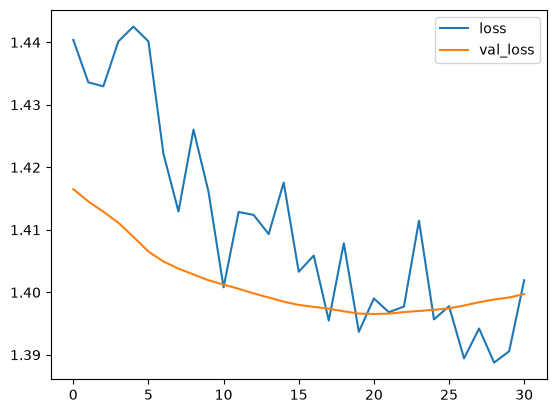

In [12]:
losses[['loss', 'val_loss']].plot()


<Axes: >

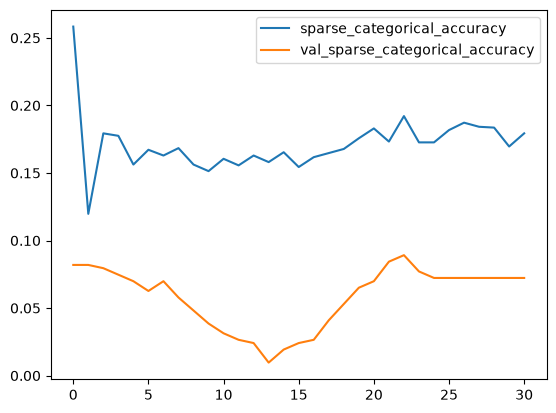

In [13]:
losses[['sparse_categorical_accuracy', 'val_sparse_categorical_accuracy']].plot()


# Evaluacion

Se evalúa validación, manteniendo juntas las fechas de los cinco escenarios.


E0000 00:00:1794268818.928501   14319 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


promedio  accuracy  precision   recall       f1  support
   macro   0.06988   0.050775 0.243519 0.056184      415
weighted   0.06988   0.013718 0.069880 0.015557      415
                clase  precision   recall       f1  support
     monitoreo_normal   0.133333 0.074074 0.095238       27
eliminacion_criaderos   0.069767 0.900000 0.129496       30
fumigacion_focalizada   0.000000 0.000000 0.000000       43
     alerta_sanitaria   0.000000 0.000000 0.000000      315


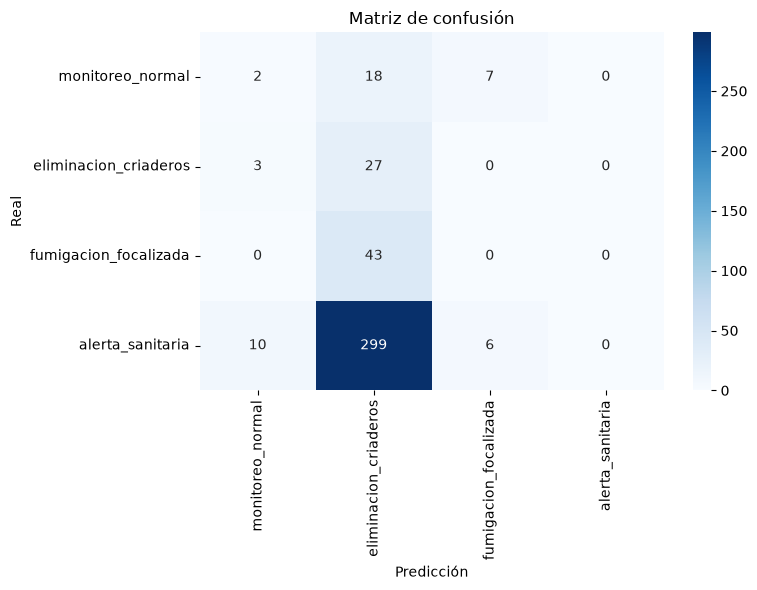

,promedio,accuracy,precision,recall,f1,support
0,macro,0.06988,0.050775,0.243519,0.056184,415
1,weighted,0.06988,0.013718,0.069880,0.015557,415


,clase,precision,recall,f1,support
0,monitoreo_normal,0.133333,0.074074,0.095238,27
1,eliminacion_criaderos,0.069767,0.900000,0.129496,30
2,fumigacion_focalizada,0.000000,0.000000,0.000000,43
3,alerta_sanitaria,0.000000,0.000000,0.000000,315


In [14]:
modelo_acciones.make_prediction(
    target='recomendacion',
    y=modelo_acciones.y_val['recomendacion'].map(dict(enumerate(categorias_acciones))),
    categorias=categorias_acciones,
    eval=True,
)
resultado = modelo_acciones.resultado
display(resultado['metricas'])
display(resultado['reporte_clasificacion'])


In [15]:
resultado['matriz_confusion']


Predicción,monitoreo_normal,eliminacion_criaderos,fumigacion_focalizada,alerta_sanitaria
Real,,,,
monitoreo_normal,2,18,7,0
eliminacion_criaderos,3,27,0,0
fumigacion_focalizada,0,43,0,0
alerta_sanitaria,10,299,6,0


In [16]:
predicciones = pd.DataFrame(index=resultado['reales'].index)
predicciones['Recomendacion_real'] = resultado['reales']['recomendacion'].to_numpy()
predicciones['Recomendacion_predicha'] = resultado['predicciones']['recomendacion'].to_numpy()
predicciones['Acierto'] = predicciones['Recomendacion_real'] == predicciones['Recomendacion_predicha']
predicciones.query('Acierto == False')


,Recomendacion_real,Recomendacion_predicha,Acierto
fecha_inicio_semana,,,
2023-04-30,monitoreo_normal,fumigacion_focalizada,False
2023-04-30,monitoreo_normal,fumigacion_focalizada,False
2023-04-30,monitoreo_normal,fumigacion_focalizada,False
2023-04-30,fumigacion_focalizada,eliminacion_criaderos,False
2023-04-30,monitoreo_normal,fumigacion_focalizada,False
...,...,...,...
2024-11-24,fumigacion_focalizada,eliminacion_criaderos,False
2024-11-24,alerta_sanitaria,eliminacion_criaderos,False
2024-11-24,alerta_sanitaria,eliminacion_criaderos,False


In [17]:
# Una vez terminado el entrenamiento, guardar si se necesita.
# nombre_archivo = '../models/ANN_Models/Acciones/ann_acciones.keras'
# modelo_acciones.model.save(nombre_archivo)
# modelo_acciones.save_load_scaler(
#     '../models/ANN_Models/Acciones/x_scaler_acciones.pkl', save=True,
# )
# Conservar también entradas_acciones y categorias_acciones, en ese orden.
